# Voyage Analytics — Data Analysis & Modeling

This notebook covers the **modeling part** of the capstone, from start to finish:

1. Business context and problem
2. Data loading, quality checks and relationships between the three datasets
3. Exploratory data analysis for each use case
4. Feature engineering and feature selection
5. Model training and validation: flight price regression, gender classification, hotel recommendation
6. Results, interpretation and conclusions

It imports the project's own modules from `src/`, so the analysis here is the same code that the API, Airflow and
Jenkins run. The full training pipeline (with MLflow tracking) is `make train`. This notebook explains it and reproduces the key steps.

## 1. Business context

A travel platform wants to use its data on **users, flights and hotel stays** to:
* **estimate flight prices** in real time (price transparency, spotting mispriced inventory);
* **classify users' gender** for audience analytics;
* **recommend hotels** to raise conversion.

Each model must be accurate, and it must also be **deployable, reproducible and maintainable**. That's why the
models are built as scikit-learn pipelines that are tracked in MLflow and served by an API.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # project root
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140, "display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

from src.data import (load_users, load_flights, load_hotels, validate, outbound_legs, route_key,
                      first_name, FLIGHT_FEATURES)
users, flights, hotels = load_users(), load_flights(), load_hotels()
print(f"users {users.shape}, flights {flights.shape}, hotels {hotels.shape}")

users (1340, 5), flights (271888, 10), hotels (40552, 8)


## 2. Data understanding

### 2.1 A first look at each dataset

In [2]:
users.head()

,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44


In [3]:
flights.head()

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,2019-09-26
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,2019-09-30
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,2019-10-03
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,2019-10-04
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,2019-10-10


In [4]:
hotels.head()

,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,2019-09-26
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,2019-10-10
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,2019-11-14
3,11,0,Hotel K,Salvador (BH),4,263.41,1053.64,2019-12-12
4,13,0,Hotel A,Florianopolis (SC),1,313.02,313.02,2019-12-26


### 2.2 Data quality
`validate()` is the same check that Airflow and Jenkins run before training.

In [5]:
print("validation:", validate())
pd.DataFrame({
    "nulls": [users.isna().sum().sum(), flights.isna().sum().sum(), hotels.isna().sum().sum()],
    "duplicate rows": [users.duplicated().sum(), flights.duplicated().sum(), hotels.duplicated().sum()],
}, index=["users", "flights", "hotels"])

validation: {'users': 1340, 'flights': 271888, 'hotels': 40552}


,nulls,duplicate rows
users,0,0
flights,0,0
hotels,0,0


### 2.3 How the datasets connect

In [6]:
legs_per_trip = flights["travelCode"].value_counts().value_counts()
print("legs per travelCode in flights:", legs_per_trip.to_dict())

out = outbound_legs(flights)
m = hotels.merge(out[["travelCode", "to"]], on="travelCode", how="left")
print(f"hotel city == outbound destination: {(m['place'] == m['to']).mean():.1%}")
print(f"users with flights: {flights['userCode'].nunique()}, with hotel stays: {hotels['userCode'].nunique()}")

legs per travelCode in flights: {2: 135944}
hotel city == outbound destination: 100.0%
users with flights: 1335, with hotel stays: 1310


**Findings**
* Every `travelCode` appears **twice** in flights: an outbound and a return leg. When we measure *where a user chose to go*,
  we use only the outbound leg (`outbound_legs`).
* Every hotel stay is in the outbound destination city, so `travelCode` links a stay to its trip.
* `userCode` links flights and hotels to `users.code`.

## 3. Exploratory analysis — flight prices

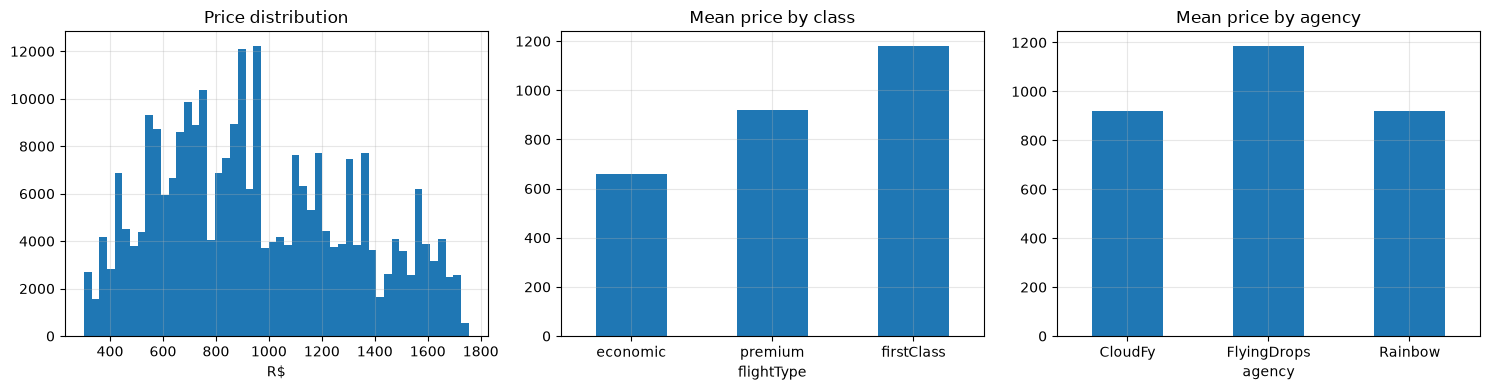

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
flights["price"].hist(bins=50, ax=axes[0]); axes[0].set(title="Price distribution", xlabel="R$")
order = ["economic", "premium", "firstClass"]
flights.groupby("flightType")["price"].mean().reindex(order).plot.bar(ax=axes[1], title="Mean price by class", rot=0)
flights.groupby("agency")["price"].mean().plot.bar(ax=axes[2], title="Mean price by agency", rot=0)
plt.tight_layout()

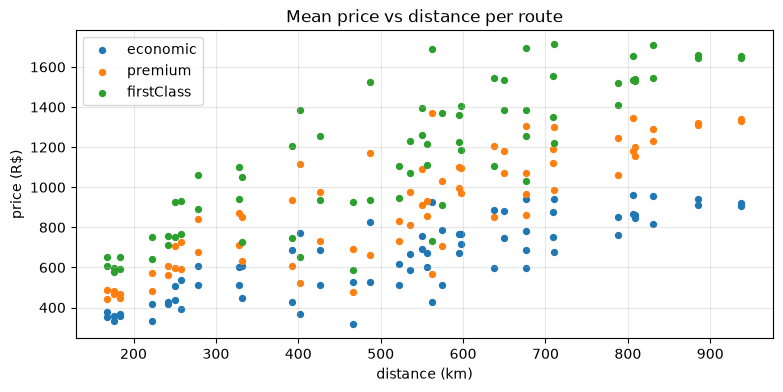

In [8]:
routes = flights.groupby(["from", "to", "flightType"]).agg(distance=("distance", "first"), price=("price", "mean")).reset_index()
for t in order:
    s = routes[routes.flightType == t]
    plt.scatter(s.distance, s.price, label=t, s=18)
plt.legend(); plt.title("Mean price vs distance per route"); plt.xlabel("distance (km)"); plt.ylabel("price (R$)");

In [9]:
group_std = flights.groupby(["from", "to", "flightType", "agency"])["price"].std()
print(f"{len(group_std)} (route, class, agency) groups - max price std within a group: {group_std.max():.4f}")
print(f"corr(time, distance) = {flights['time'].corr(flights['distance']):.4f}")
print(f"distances per route: {flights.groupby(['from','to'])['distance'].nunique().max()}")
by_month = flights.assign(m=flights.date.dt.month).groupby("m")["price"].mean()
print(f"mean price by month ranges {by_month.min():.0f}-{by_month.max():.0f} (no seasonality)")

490 (route, class, agency) groups - max price std within a group: 0.0000
corr(time, distance) = 1.0000
distances per route: 1
mean price by month ranges 951-963 (no seasonality)


**Findings that drive feature selection**
* Price rises with **distance** and **cabin class**. FlyingDrops is ~29% more expensive than the other agencies.
* Within each (route, class, agency) group the price **never varies**, so the price is a deterministic lookup.
* `time` is perfectly correlated with `distance` (it's redundant), and dates don't affect price.

➡️ **Selected features:** `from`, `to`, `flightType`, `agency`, `distance`.
`time` and calendar features are dropped. An ablation run in MLflow confirms they add nothing.

## 4. Exploratory analysis — users & gender

Sample of users labelled 'none': ['Trina Thomas', 'Jack Sabo', 'Debbie Helms', 'Irene Tucker', 'Victor Tribbett', 'Tanya Orourke', 'Christopher Elliott', 'Helen Selby']


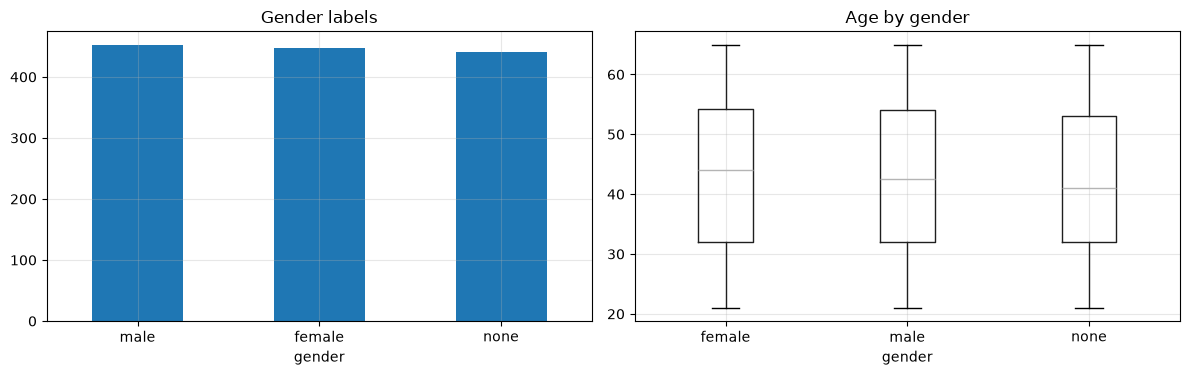

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
users["gender"].value_counts().plot.bar(ax=axes[0], title="Gender labels", rot=0)
users.boxplot(column="age", by="gender", ax=axes[1]); axes[1].set_title("Age by gender"); plt.suptitle("")
plt.tight_layout()
print("Sample of users labelled 'none':", users[users.gender == "none"]["name"].head(8).tolist())

**Findings**
* A third of users are labelled **`none`**, and they have ordinary gendered names. So `none` means *not disclosed*
  and can't be inferred. The served model predicts **male / female**.
* Age (and, as tested below, company and travel behaviour) is nearly identical across genders, so the **first name**
  is the useful signal.

## 5. Exploratory analysis — destinations & hotels

hotels:                                mean  std  count
name     place                                 
Hotel A  Florianopolis (SC)   313.0  0.0   3330
Hotel AF Sao Paulo (SP)       139.1  0.0   4828
Hotel AU Recife (PE)          312.8  0.0   4467
Hotel BD Natal (RN)           242.9  0.0   4829
Hotel BP Brasilia (DF)        247.6  0.0   4437
Hotel BW Campo Grande (MS)     60.4  0.0   4333
Hotel CB Rio de Janeiro (RJ)  166.0  0.0   5029
Hotel K  Salvador (BH)        263.4  0.0   5094
Hotel Z  Aracaju (SE)         208.0  0.0   4205


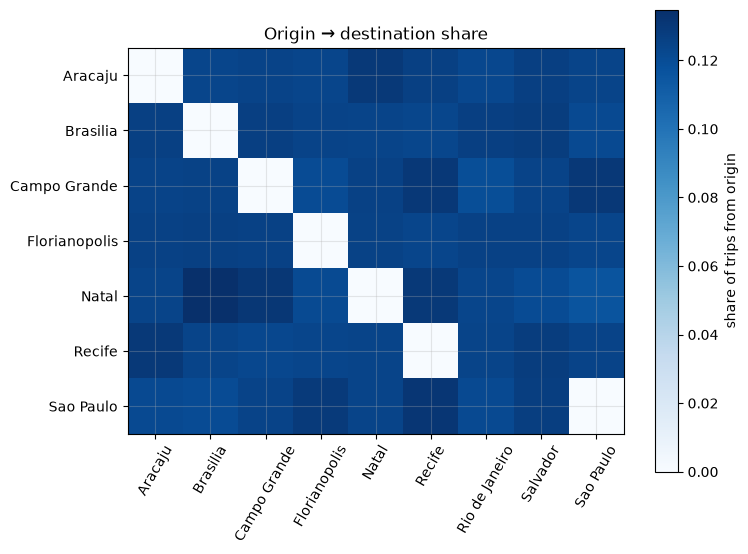

In [11]:
od = pd.crosstab(out["from"], out["to"], normalize="index")
plt.figure(figsize=(8, 6)); plt.imshow(od, cmap="Blues"); plt.colorbar(label="share of trips from origin")
plt.xticks(range(len(od.columns)), [c.split(" (")[0] for c in od.columns], rotation=60)
plt.yticks(range(len(od.index)), [c.split(" (")[0] for c in od.index]); plt.title("Origin → destination share");
print("hotels:", hotels.groupby(["name", "place"])["price"].agg(["mean", "std", "count"]).round(1).to_string())

In [12]:
c = pd.crosstab(hotels["userCode"], hotels["place"])
top_share = (c.max(axis=1) / c.sum(axis=1))
print(f"cities visited per user (median): {(c > 0).sum(axis=1).median():.0f} of 9")
print(f"share of a user's stays in their most visited city (median): {top_share.median():.1%}")

cities visited per user (median): 8 of 9
share of a user's stays in their most visited city (median): 22.1%


**Findings**
* There are **9 hotels, one per city**, each with a fixed nightly price, so recommending a hotel means recommending a destination.
* From every origin, destinations are spread almost evenly (~12.5% each), and users visit most cities.
  There is **little preference signal**, so a recommender can only modestly beat a random baseline. We measure
  exactly that.

## 6. Model 1 — Flight price regression

**Validation design.**
* **Time-based split:** train on older flights, test on the newest 20%. This mirrors production, where the model predicts future bookings.
* **Unseen-route check:** routes held out entirely, to test generalisation to routes the model has never seen.

The cell below reproduces the comparison on a sample for speed. The full run (all rows, MLflow logging) is
`python -m src.train_flight_price`.

In [13]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from src.train_flight_price import build_pipeline, evaluate

df = flights.copy()
df["route"] = [route_key(a, b) for a, b in zip(df["from"], df["to"])]
cutoff = df["date"].quantile(0.8)
train, test = df[df.date < cutoff].sample(60_000, random_state=42), df[df.date >= cutoff]

candidates = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, random_state=42),
}
rows, fitted = [], {}
for name, est in candidates.items():
    pipe = build_pipeline(est).fit(train[FLIGHT_FEATURES], train["price"])
    fitted[name] = pipe
    m = evaluate(test["price"], pipe.predict(test[FLIGHT_FEATURES]))
    sample = df.sample(30_000, random_state=0)
    r2 = [evaluate(sample.iloc[b]["price"], clone(pipe).fit(sample.iloc[a][FLIGHT_FEATURES], sample.iloc[a]["price"])
                   .predict(sample.iloc[b][FLIGHT_FEATURES]))["r2"]
          for a, b in GroupKFold(5).split(sample, groups=sample["route"])]
    rows.append({"model": name, **{k: round(v, 3) for k, v in m.items()}, "unseen_route_r2": round(np.mean(r2), 3)})
pd.DataFrame(rows).set_index("model")

2026/10/13 10:47:25 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/pranati/travel-mlops/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,rmse,mae,r2,mape,unseen_route_r2
model,,,,,
Ridge,102.177,80.401,0.921,10.210,0.889
RandomForest,0.000,0.000,1.000,0.000,0.766
HistGradientBoosting,3.121,2.341,1.000,0.284,0.793


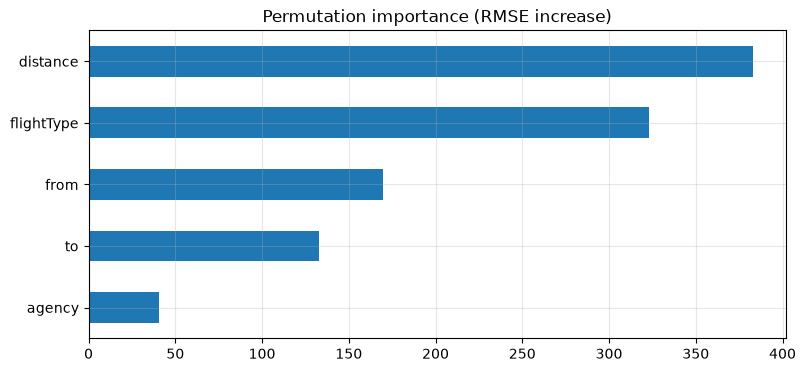

In [14]:
from sklearn.inspection import permutation_importance
best = fitted["RandomForest"]
s = test.sample(3000, random_state=0)
imp = permutation_importance(best, s[FLIGHT_FEATURES], s["price"], n_repeats=5, random_state=0,
                             scoring="neg_root_mean_squared_error")
pd.Series(imp.importances_mean, index=FLIGHT_FEATURES).sort_values().plot.barh(
    title="Permutation importance (RMSE increase)");

**Interpretation**
* **Random Forest reproduces future prices almost exactly** (R² ≈ 1.0), because the price is a lookup over route × class × agency.
  The test rows are *later in time* than the training rows, so this is not leakage.
* **On unseen routes, Ridge generalises best.** It learns additive city effects plus a distance slope, while the trees memorise routes.
  **Design decision:** the API serves Random Forest for known routes and Ridge as an automatic fallback for new routes.
* **Importance ranking:** distance > cabin class > origin > destination > agency, which matches business intuition.

## 7. Model 2 — Gender classification

Features: TF-IDF of first-name character 2–4-grams + logistic regression.

Validation:
* **Stratified 5-fold CV**;
* **GroupKFold by first name** (unseen names).

              precision    recall  f1-score   support

      female       0.88      0.91      0.90       448
        male       0.91      0.88      0.89       452

    accuracy                           0.89       900
   macro avg       0.89      0.89      0.89       900
weighted avg       0.90      0.89      0.89       900



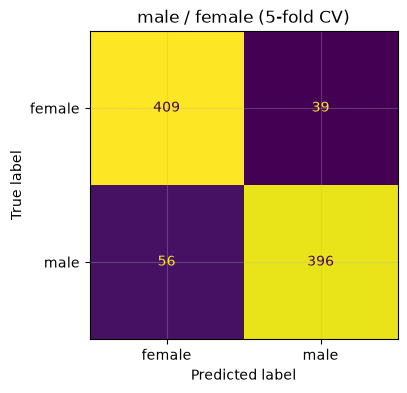

In [15]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.train_gender import name_pipeline

u = users.assign(first_name=users["name"].map(first_name))
binary = u[u.gender != "none"]
pred = cross_val_predict(name_pipeline(), binary, binary["gender"], cv=StratifiedKFold(5, shuffle=True, random_state=42))
print(classification_report(binary["gender"], pred))
ConfusionMatrixDisplay.from_predictions(binary["gender"], pred, colorbar=False); plt.title("male / female (5-fold CV)");

In [16]:
pred3 = cross_val_predict(name_pipeline(), u, u["gender"], cv=StratifiedKFold(5, shuffle=True, random_state=42))
print(f"3-class accuracy incl. 'none': {(pred3 == u['gender']).mean():.1%}  (vs ~89% for male/female)")

3-class accuracy incl. 'none': 54.3%  (vs ~89% for male/female)


**Interpretation:** about **89% accuracy and 0.89 macro F1** for male/female, with balanced precision and recall.
Adding `none` as a class drops accuracy to about 54%, which confirms it can't be predicted from a name.
*Note:* inferring gender from a name is unreliable and gender isn't binary. Use this only for aggregate analytics.

## 8. Model 3 — Hotel recommendation

The hybrid score blends history, item-item collaborative similarity, popularity, budget fit and a **home-city penalty**.
Weights are tuned by grid search on a per-user **temporal** validation window, then scored on a later, untouched test window.
The full procedure is `python -m src.train_recommender`. Here we load its logged results.

tuned weights: {'history': 0.0, 'similar': 0.5, 'popularity': 0.0, 'budget': 0.0, 'home_penalty': 3.0}


,hit_at_1,hit_at_3,mrr,ndcg_at_3
random,0.105,0.329,0.310,0.232
popularity,0.126,0.365,0.333,0.261
history_only,0.123,0.367,0.333,0.261
hybrid_tuned,0.126,0.375,0.339,0.266


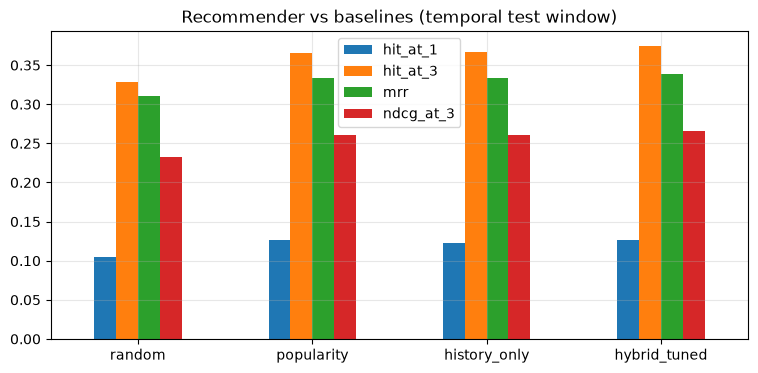

In [17]:
import json
rec = json.loads(Path("../models/metrics/recommender.json").read_text())
print("tuned weights:", rec["weights"])
res = pd.DataFrame(rec["test"]).T[["hit_at_1", "hit_at_3", "mrr", "ndcg_at_3"]].astype(float).round(3)
res.plot.bar(rot=0, title="Recommender vs baselines (temporal test window)", figsize=(9, 4)); res

In [18]:
import joblib
model = joblib.load("../models/hotel_recommender.joblib")
pd.DataFrame(model.recommend(0, k=5))[["name", "place", "avg_price", "reason"]]

,name,place,avg_price,reason
0,Hotel CB,Rio de Janeiro (RJ),165.99,Travellers with similar bookings chose this
1,Hotel BW,Campo Grande (MS),60.39,Travellers with similar bookings chose this
2,Hotel BD,Natal (RN),242.88,Travellers with similar bookings chose this
3,Hotel AF,Sao Paulo (SP),139.10,Travellers with similar bookings chose this
4,Hotel K,Salvador (BH),263.41,Travellers with similar bookings chose this


**Interpretation:** with 9 hotels, a random ranking already gets hit@3 ≈ 0.33. The tuned hybrid reaches **0.375**
(+14% relative), and beats popularity and history-only. The strongest signal is that people **don't book hotels in
their home city**. The gain is modest because, as the EDA showed, this data has very little destination preference.
On real booking data, the same tuning would automatically put more weight on history and budget.

## 9. Conclusions

| Model | Metric (held-out) | Result |
|---|---|---|
| Flight price — Random Forest | R² / RMSE on future flights | 1.000 / ≈ 0 |
| Flight price — Ridge fallback | R² on unseen routes | 0.88 |
| Gender — char n-gram logistic regression | accuracy / macro F1 (5-fold CV) | 0.894 / 0.894 |
| Hotel recommender — tuned hybrid | hit@3 vs random / popularity | 0.375 vs 0.329 / 0.365 |

**Key takeaways**
1. EDA drove the design. Deterministic prices, redundant `time`, and the meaning of the `none` label all changed the features and the models.
2. The validation design (time-based and unseen-route splits, temporal recommender evaluation) matters more than the choice of algorithm.
3. Every model is a single sklearn pipeline (preprocessing + model). It is logged to MLflow, served by the Flask API, and
   retrained by Airflow and Jenkins with quality gates. See the [README](../README.md) for the MLOps side.